In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

from sklearn.decomposition import PCA

from sklearn.pipeline import Pipeline


import os
os.chdir(r'E:\Backup Files Abhinav_Satyam\Practical Machine Learning\Sanjay Sir Git Repo\Datasets')

In [3]:
df = pd.read_csv('nutrient.csv', index_col = 0)
df

,energy,protein,fat,calcium,iron
Food_Item,,,,,
BEEF BRAISED,340,20,28,9,2.6
HAMBURGER,245,21,17,9,2.7
BEEF ROAST,420,15,39,7,2.0
BEEF STEAK,375,19,32,9,2.6
BEEF CANNED,180,22,10,17,3.7
CHICKEN BROILED,115,20,3,8,1.4
CHICKEN CANNED,170,25,7,12,1.5
BEEF HEART,160,26,5,14,5.9
LAMB LEG ROAST,265,20,20,9,2.6


In [4]:
scl = StandardScaler().set_output(transform='pandas')
scl_data = scl.fit_transform(df)
scl_data

,energy,protein,fat,calcium,iron
Food_Item,,,,,
BEEF BRAISED,1.335059,0.239681,1.314297,-0.456581,0.152385
HAMBURGER,0.378515,0.479361,0.318516,-0.456581,0.222121
BEEF ROAST,2.140569,-0.958723,2.310078,-0.482699,-0.266028
BEEF STEAK,1.687470,0.000000,1.676399,-0.456581,0.152385
BEEF CANNED,-0.275962,0.719042,-0.315163,-0.352109,0.919476
CHICKEN BROILED,-0.930439,0.239681,-0.948842,-0.469640,-0.684442
CHICKEN CANNED,-0.376651,1.438084,-0.586740,-0.417404,-0.614706
BEEF HEART,-0.477340,1.677764,-0.767791,-0.391286,2.453658
LAMB LEG ROAST,0.579893,0.239681,0.590093,-0.456581,0.152385


In [8]:
hc = AgglomerativeClustering(n_clusters=3)
hc.fit(scl_data)
hc.labels_
 

array([1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 2, 2, 0, 0, 0, 0,
       0, 0, 0, 0, 0])

In [14]:
pca = PCA().set_output(transform='pandas')
pca_data = pca.fit_transform(scl_data)

pca_data['Cluster'] = hc.labels_
pca_data

,pca0,pca1,pca2,pca3,pca4,Cluster
Food_Item,,,,,,
BEEF BRAISED,1.894907,0.318029,-0.003579,0.327156,0.005915,1
HAMBURGER,0.659812,-0.079563,-0.512841,0.166202,-0.002632,0
BEEF ROAST,2.936755,1.122724,1.097788,-0.226335,0.003483,1
BEEF STEAK,2.321069,0.585663,0.239173,0.318095,0.028400,1
BEEF CANNED,-0.256477,0.054382,-1.168707,0.474857,-0.042641,0
CHICKEN BROILED,-0.932996,-0.905719,-0.393767,-0.815849,-0.031897,0
CHICKEN CANNED,-0.185016,-1.564189,-0.789681,0.039419,-0.015362,0
BEEF HEART,-0.699024,0.346282,-2.595080,1.568667,0.045738,0
LAMB LEG ROAST,0.937389,0.108904,-0.274877,0.082978,-0.024877,0


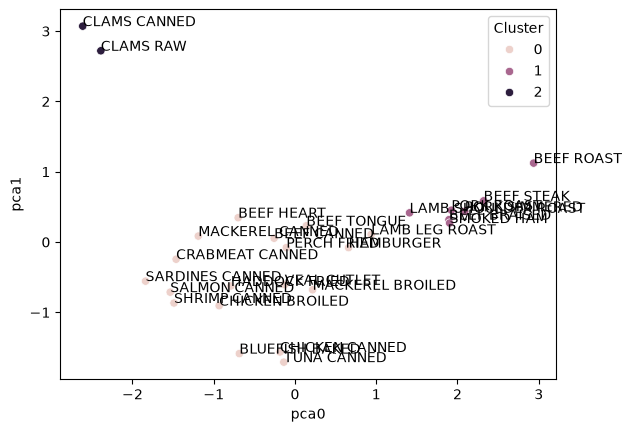

In [16]:
sns.scatterplot(data = pca_data , x = 'pca0', y='pca1', hue='Cluster')
for i in range(len(df)):
    plt.text(pca_data['pca0'].iloc[i] , pca_data['pca1'].iloc[i] , df.index[i])